# 1. Initial Configurations

In [1]:
# Configuration and library imports
import boto3
import awswrangler as wr

# Analysis libraries
import numpy as np
import pandas as pd
import pyarrow as pa
import json
from ydata_profiling import ProfileReport
from datetime import datetime

# Visualization libraries
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

c:\Users\ana.esquinelato\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# # Database configurations
# DATABASE = "db_data_raw_elo"
# OUTPUT_BUCKET = ""
# region_name = "us-east-1"

# session = boto3.Session(profile_name='AnaHatsue')
# glue_client = session.client("glue", region_name=region_name)
# s3_resource = session.client('s3',region_name='uregion_name')

# 2. Get data

## List columns and types from Glue

In [3]:
# # Table name
# table_name = "tb_clients"

# original_athena_types = {} # Column types dictionary
# columns_from_glue = []     # Column names list
# select_columns_str = "*"   # Default
# percentual_sample = 0.05 # 5% sample

# try:
#     glue_response = glue_client.get_table(DatabaseName=DATABASE, Name=table_name)
#     glue_columns_meta = glue_response["Table"]["StorageDescriptor"]["Columns"]
#     for c_meta in glue_columns_meta:
#         col_name = c_meta["Name"]
#         col_type = c_meta["Type"].lower() # Needs to be lower case for comparison later
#         columns_from_glue.append(col_name)
#         original_athena_types[col_name] = col_type
    
#     # Needs to be in the same order as in Glue/Athena
#     select_columns_str = ", ".join([f'"{c}"' for c in columns_from_glue]) 
    
#     print(f"Schema obtido do Glue. Total de colunas: {len(columns_from_glue)}")
    
#     print(f"Schema obtido do Glue. Total de colunas: {len(columns_from_glue)}\nTipos originais do Athena/Glue:")
#     for i, (col, dtype) in enumerate(original_athena_types.items()):
#         print(f"  {col}: {dtype}")
# except Exception as e:
#     print(f"Erro ao obter schema do Glue: {e}. Usando SELECT * e não teremos os tipos de referência do Glue.")
#     # Sem original_athena_types, a comparação e conversão assistida ficam limitadas.

## Code to execute SQL Query

In [4]:
# query_athena = f"""
# SELECT {select_columns_str}
# FROM {DATABASE}.{table_name}
# TABLESAMPLE BERNOULLI({percentual_sample}) 
# """ # Makes a random sample where every line has a percentage of being included

# print(f"\nExecutando query no Athena para amostrar {percentual_sample}% da tabela {table_name}.")
# try:
#     athena_response = wr.athena.read_sql_query(
#         boto3_session=session,
#         sql=query_athena,
#         database=DATABASE,
#         s3_output={OUTPUT_BUCKET},
#         ctas_approach=True # Create Table As Select approach for better performance
#         keep_files=False,
#         dtype_backend="pyarrow"
#     )
#     print("Amostra Athena (linhas × colunas):", athena_response.shape)

# except Exception as e:
#     print(f"Erro ao executar query no Athena: {e}")
#     athena_response = pd.DataFrame()

# df_sample = athena_response

## Using a test Dataset

In [5]:
cols_canon = ['threeDSCompInd', 'purchaseDate', 'transStatus', 'purchaseAmount']

In [6]:
test_data = pd.read_csv('../bases_de_dados/sintetica/dataset_sintetico.csv', encoding='latin1')

df_sample = test_data

C:\Users\ana.esquinelato\AppData\Local\Temp\ipykernel_13116\305579670.py:1: DtypeWarning: Columns (51,60,61,62,63) have mixed types. Specify dtype option on import or set low_memory=False.
  test_data = pd.read_csv('../bases_de_dados/sintetica/dataset_sintetico.csv', encoding='latin1')


# 3. Data Overview and Descriptive Statistics

_What am I working with?_

To have a deep understanding of the data, to handle it efficiently in future machine learning tasks.
Start by characterizing the data to the number and types of features, missing rate and percentage of duplicate observations.

## Create versions

In [7]:
sample_v1 = df_sample.copy()
# sample_v2 = sample_v1.copy()

curr_version = sample_v1

## Missing Values

### Check rows with all missing values

In [8]:
rows_all_missing = curr_version[curr_version.isnull().all(axis=1)]

print(f'\nEncontradas {len(rows_all_missing)} linhas com todos os valores ausentes.')


Encontradas 0 linhas com todos os valores ausentes.


#### Drop rows with all missing values

In [9]:
curr_version.drop(rows_all_missing.index, inplace=True)

### Check missing values per column

In [10]:
# Creates a Series with count and percentage of missing values per column
missing_values = curr_version.isnull().sum()
missing_percentage = (missing_values / len(curr_version)) * 100
missing_df = pd.DataFrame({'count': missing_values.values, 'percentage': missing_percentage})
missing_df = missing_df[missing_df['count'] > 0].sort_values(by='percentage', ascending=False)

print("Colunas com valores ausentes (ordenado por %):")
print(missing_df)

# List columns with +80% missing values
limit_nuls = 80
most_missing_values_df = missing_df[missing_df['percentage'] > limit_nuls]
most_missing_values_ls = most_missing_values_df.index.tolist()

Colunas com valores ausentes (ordenado por %):
                              count  percentage
billAddrLine3                 10000      100.00
shipAddrLine2                 10000      100.00
shipAddrLine3                 10000      100.00
billAddrLine2                 10000      100.00
sellerInfo                     9528       95.28
multiTransaction               9528       95.28
payTokenInfo                   9493       94.93
payTokenInd                    9493       94.93
recurringDate                  9024       90.24
paymentInfo                    9024       90.24
recurringFrequency             9024       90.24
recurringExpiry                9024       90.24
recurringInd                   9024       90.24
recurringCurrency              9024       90.24
recurringAmount                9024       90.24
threeRIInd                     9024       90.24
acctInfo                       9015       90.15
transStatusReason              9015       90.15
threeDSRequestorChallengeInd   8567      

### Negative or Zero purchaseAmount

In [11]:
# Not all missing values means the same, sometimes they indicate special cases (ex: returns or cancellations)

# Check if values in Purchase_Amount are zero or negative
negative_purchase_amounts = curr_version[curr_version['purchaseAmount'] <= 0]

print(f'\nEncontradas {str(sum(negative_purchase_amounts['purchaseAmount'] == 0))} linhas com valor igual a zero e {str(sum(negative_purchase_amounts['purchaseAmount'] < 0))} linhas com valores negativos em purchaseAmount.')


Encontradas 0 linhas com valor igual a zero e 0 linhas com valores negativos em purchaseAmount.


#### Drop values with Zero or Negative Purchase_Amount

In [12]:
curr_version.drop(columns=negative_purchase_amounts.index, inplace=True)

print(f'\n{str(sum(negative_purchase_amounts['purchaseAmount'] == 0))} linhas excluídas com valor igual a zero em purchaseAmount.') 
print(f'\n{str(sum(negative_purchase_amounts['purchaseAmount'] < 0))} linhas excluídas com valores negativos em purchaseAmount.')


0 linhas excluídas com valor igual a zero em purchaseAmount.

0 linhas excluídas com valores negativos em purchaseAmount.


#### Drops columns with +80% of missing values

In [13]:
# Delete columns with +80% missing values and updates lists

curr_version.drop(columns=[col for col in most_missing_values_ls if col not in cols_canon], inplace=True)

print(f'\n{len(most_missing_values_df)} Colunas excluídas por conter mais de {limit_nuls}% de valores ausentes.')


20 Colunas excluídas por conter mais de 80% de valores ausentes.


## Unique Values

### Special Cases with Unique Values

In [14]:
# # Important values like purchase amount, purchase date or location should be included in the analysis as a group

# # Creates bin for purchase amount
# curr_version['purchaseAmountBin'] = pd.qcut(curr_version['purchaseAmount'], q=5)

# # Transforms in string and in datetime
# curr_version['purchaseDateTime'] = pd.to_datetime(curr_version['purchaseDate'].astype(str), format='%Y%m%d%H%M%S', errors='coerce')
# curr_version['purchaseMonth'] = curr_version['purchaseDateTime'].dt.to_period('M')

# # Creates bins for time of day
# curr_version['purchaseTime'] = curr_version['purchaseDateTime'].dt.hour
# bins_time = [0, 6, 12, 18, 24]
# curr_version['purchaseTimeBin'] = pd.cut(curr_version['purchaseTime'], bins=bins_time, right=False)

# # Creates bins for day of the week
# curr_version['purchaseDate'] = curr_version['purchaseDateTime'].dt.date
# curr_version['purchaseDateBin'] = curr_version['purchaseDateTime'].dt.weekday

# # Groups Billing location
# # curr_version['billLocation'] = curr_version['billAddrCity'] + ' - ' + curr_version['billAddrState']
# curr_version['billLocation'] = curr_version['billAddrState']

# # Groups by year
# curr_version['cardExpiryDate'] = pd.to_datetime(curr_version['cardExpiryDate'].astype(str), format='%y%m')
# curr_version['cardExpiryDate'] = curr_version['cardExpiryDate'].dt.to_period('M').dt.to_timestamp()
# curr_version['dateDiff'] = (curr_version['cardExpiryDate'] - curr_version['purchaseDateTime']).dt.days

# # Creates bin per period
# bins_period = [60, 180, 365, 730, 1825, 3650]
# curr_version['dateDiffBin'] = pd.cut(curr_version['dateDiff'], bins=bins_period, right=False)

# # Group browserUserAgent
# for line in curr_version['browserUserAgent'].items():
#     if 'Chrome' in line[1]:
#         curr_version.at[line[0], 'browserUserAgent'] = 'Chrome'
#     elif 'Firefox' in line[1]:
#         curr_version.at[line[0], 'browserUserAgent'] = 'Firefox'
#     elif 'Safari' in line[1]:
#         curr_version.at[line[0], 'browserUserAgent'] = 'Safari'
#     elif 'Edge' in line[1]:
#         curr_version.at[line[0], 'browserUserAgent'] = 'Edge'
#     else:
#         curr_version.at[line[0], 'browserUserAgent'] = 'Other'

In [15]:
# Drop newly created columns that won't be used in the analysis
# curr_version.drop(columns=['purchaseDate', 'purchaseDateTime', 'purchaseTime', 'billAddrCity', 'billAddrState', 'shipAddrCity', 'shipAddrState', 'cardExpiryDate', 'dateDiff'], inplace=True) # Não excluir a coluna purchaseAmount para fazer operações futuras

### Higher Cardinality

In [16]:
unique_values = curr_version.nunique()
porcentage_uniques = (unique_values / len(curr_version)) * 100

unique_df = pd.DataFrame({'count': porcentage_uniques.values, 'percentage': porcentage_uniques})
unique_df = unique_df[unique_df['count'] > 0].sort_values(by='percentage', ascending=False)

limit_unique = 99
most_unique_values_df = unique_df[unique_df['percentage'] > limit_unique]

print("Colunas com maiores valores únicos:")
print(unique_df.head(15))

Colunas com maiores valores únicos:
                       count  percentage
browserIP             100.00      100.00
threeDSServerTransID  100.00      100.00
merchantDocument      100.00      100.00
cardHolderDocument    100.00      100.00
acctNumber            100.00      100.00
billAddrPostCode       99.95       99.95
shipAddrPostCode       99.89       99.89
purchaseDate           99.86       99.86
shipAddrLine1          99.35       99.35
billAddrLine1          99.31       99.31
email                  92.54       92.54
purchaseAmount         88.05       88.05
browserUserAgent       84.17       84.17
cardholderName         79.32       79.32
shipAddrCity           37.53       37.53


### Low Cardinality

In [17]:
# Columns with only one value
least_distinct = unique_values[unique_values == 1]
least_distinct_values_ls = least_distinct.index.tolist()

print("Colunas com apenas um valor:")
print(least_distinct)

Colunas com apenas um valor:
messageType         1
messageVersion      1
purchaseExponent    1
threeDSCompInd      1
transType           1
messageExtension    1
dtype: int64


### Drop Unique Values

In [18]:
most_unique_values_df.index

Index(['browserIP', 'threeDSServerTransID', 'merchantDocument',
       'cardHolderDocument', 'acctNumber', 'billAddrPostCode',
       'shipAddrPostCode', 'purchaseDate', 'shipAddrLine1', 'billAddrLine1'],
      dtype='object')

In [19]:
# curr_version.drop(columns=most_unique_values_df.index, inplace=True)

curr_version.drop(columns=[col for col in most_unique_values_df.index if col not in cols_canon], inplace=True)

curr_version.drop(columns=[col for col in least_distinct.index if col not in cols_canon], inplace=True)

# curr_version.drop(columns=least_distinct.index, inplace=True)

# lst_deleted = ', '.join(most_unique_values_df.index.astype(str))

# print(f'{len(most_unique_values_df)} Colunas excluídas que continham mais de 90% dos valores únicos:')
# print(most_unique_values_df)

# print(f'\n{len(least_distinct)} Colunas excluídas que continham apenas 01 valor único:')
# print(least_distinct)

## Duplicates Values

In [20]:
duplicate_df = curr_version[curr_version.duplicated(keep=False)]

print(f'\nEncontradas {len(duplicate_df)} linhas duplicadas no dataset.')


Encontradas 0 linhas duplicadas no dataset.


### Drops the duplicates value

In [21]:
curr_version.drop_duplicates()

print(f'{len(duplicate_df)} Linhas excluídas com valores duplicados.')

0 Linhas excluídas com valores duplicados.


## Manual Analysis

In [22]:
curr_version.drop(columns=
    [
        'messageCategory', # Só tem valor 1 e 8, não sei o que é
        # 'deviceChannel', # Só tem valor 1, 2 ou 3, não faz sentido manter porque existe o browserUserAgent
        'browserTZ', # Talvez pra comparar com o fuso horário do usuário
        # 'browserScreenHeight', # Não faz sentido manter porque tem browserUserAgent
        # 'browserScreenWidth', # Não faz sentido manter porque tem browserUserAgent
        'cardholderName', # Alta cardinalidade, problemas com compliance
        # 'cardExpiryDate', # Talvez porque pode ser usado para fraude
        'merchantName', # Deveria ficar o merchantDocument, por motivos de compliance, mas tem alta cardinalidade também
        'cardSecurityCode', # Alta cardinalidade, problemas com compliance
        # 'eci', # 5 risco do emissor ou 6 risco da bandeira, 7 autenticação não realizada risco do estabelecimento
        # 'challengeWindowSize',
        'billAddrCountry', # Há a possibilidade de uso de VPN pra fraude
        'shipAddrCountry'
    ], inplace=True)

In [23]:
# curr_version['purchaseCurrency'] = curr_version['purchaseCurrency'].astype('int64')
# curr_version['merchantCountryCode'] = curr_version['merchantCountryCode'].astype('category')
curr_version['transStatus'] = curr_version['transStatus'].astype('bool')
# curr_version['eci'] = curr_version['eci'].astype('category')
curr_version['fraud_label'] = curr_version['fraud_label'].astype('bool')
curr_version['addrMatch'] = curr_version['addrMatch'].astype('bool')
# curr_version['purchaseDateBin'] = curr_version['purchaseDateBin'].astype('category')
# curr_version['billLocation'] = curr_version['billLocation'].astype('category')

In [24]:
curr_version.dtypes

productType             object
purchaseCurrency         int64
merchantCountryCode      int64
deviceChannel            int64
threeDSCompInd          object
browserLanguage         object
purchaseInstalData       int64
purchaseDate             int64
browserScreenHeight      int64
browserScreenWidth       int64
browserUserAgent        object
cardExpiryDate           int64
email                   object
transStatus               bool
eci                      int64
challengeWindowSize    float64
purchaseAmount           int64
fraud_label               bool
billAddrCity            object
billAddrState           object
shipAddrCity            object
shipAddrState           object
addrMatch                 bool
dtype: object

In [201]:
curr_version.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
productType,10000,3,ONLINE_PURCHASE,6929,NaN,NaN,NaN,NaN,NaN,NaN,NaN
purchaseCurrency,10000.0,NaN,NaN,NaN,971.2928,43.313364,840.0,986.0,986.0,986.0,986.0
merchantCountryCode,10000.0,NaN,NaN,NaN,133.3914,193.138979,76.0,76.0,76.0,76.0,840.0
deviceChannel,10000.0,NaN,NaN,NaN,1.8136,0.419372,1.0,2.0,2.0,2.0,3.0
threeDSCompInd,10000,1,Y,10000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
browserLanguage,10000,3,pt-BR,6916,NaN,NaN,NaN,NaN,NaN,NaN,NaN
purchaseInstalData,10000.0,NaN,NaN,NaN,1.3977,0.659529,1.0,1.0,1.0,2.0,3.0
purchaseDate,10000.0,NaN,NaN,NaN,20251011468991.207031,18797074.266925,20250929191017.0,20251007062551.5,20251014204405.0,20251022030958.0,20251029190209.0
browserScreenHeight,10000.0,NaN,NaN,NaN,1122.0069,277.76469,640.0,883.0,1118.0,1364.0,1599.0
browserScreenWidth,10000.0,NaN,NaN,NaN,1756.9924,459.994493,960.0,1358.0,1755.0,2158.25,2559.0


## Update list of deleted and kept columns

In [202]:
# Create varibles with different types of columns

deleted_cols = []
kept_cols = []
types_cols_kept = []

In [203]:
# Update kept columns list
for col in curr_version.columns:
    kept_cols.append(col)

print(f'\nColunas mantidas:\n{kept_cols}')

# Update column type list after dropping columns using columns as guides
types_cols_kept = curr_version.dtypes

# Update deleted columns list
deleted_cols = list(set(df_sample.columns) - set(curr_version.columns))

print(f'\nColunas excluídas:\n{deleted_cols}')

print(f'\n{len(kept_cols)} colunas mantidas. {len(deleted_cols)} colunas excluídas.')
print(f'\nTipos das colunas mantidas: \n{types_cols_kept}')


Colunas mantidas:
['productType', 'purchaseCurrency', 'merchantCountryCode', 'deviceChannel', 'threeDSCompInd', 'browserLanguage', 'purchaseInstalData', 'purchaseDate', 'browserScreenHeight', 'browserScreenWidth', 'browserUserAgent', 'cardExpiryDate', 'email', 'transStatus', 'eci', 'challengeWindowSize', 'purchaseAmount', 'fraud_label', 'billAddrCity', 'billAddrState', 'shipAddrCity', 'shipAddrState', 'addrMatch']

Colunas excluídas:
['transType', 'billAddrLine1', 'threeDSServerTransID', 'sdkTransID', 'cardHolderDocument', 'messageType', 'threeRIInd', 'recurringCurrency', 'browserIP', 'messageVersion', 'merchantName', 'payTokenInfo', 'shipAddrPostCode', 'sellerInfo', 'messageExtension', 'threeDSRequestorChallengeInd', 'cardholderName', 'messageCategory', 'merchantDocument', 'browserTZ', 'recurringExpiry', 'acctInfo', 'billAddrCountry', 'acctNumber', 'billAddrLine2', 'paymentInfo', 'recurringDate', 'cardSecurityCode', 'shipAddrLine2', 'recurringFrequency', 'transStatusReason', 'payToke

## Separation between column types

In [204]:
print("Dimensões da amostra (linhas × colunas):", curr_version.shape)
print("\nInformações gerais e tipos de dados:")
curr_version.info(verbose=True, show_counts=True)

# Separate columns by data type
numeric_cols = []
string_cols = []
datetime_cols = []
date_cols = []
bool_cols = []
other_cols = []

# Classification based on pandas and pyarrow dtypes
for col, dtype in types_cols_kept.items():
    if pd.api.types.is_numeric_dtype(dtype) and not pd.api.types.is_bool_dtype(dtype):
        numeric_cols.append(col)
    elif pd.api.types.is_string_dtype(dtype) or \
         (isinstance(dtype, pd.ArrowDtype) and (pa.types.is_string(dtype.pyarrow_dtype) or pa.types.is_large_string(dtype.pyarrow_dtype))):
        string_cols.append(col)
    elif isinstance(dtype, pd.ArrowDtype) and pa.types.is_date(dtype.pyarrow_dtype):
        date_cols.append(col_name)
    elif pd.api.types.is_datetime64_any_dtype(dtype) or \
         (isinstance(dtype, pd.ArrowDtype) and pa.types.is_timestamp(dtype.pyarrow_dtype)):
        datetime_cols.append(col)
    elif pd.api.types.is_bool_dtype(dtype):
        bool_cols.append(col)
    else:
        other_cols.append(col)

print(f"Colunas numéricas: {len(numeric_cols)}")
print(f"Colunas textuais: {len(string_cols)}")
print(f"Colunas datetime: {len(datetime_cols)}")
print(f"Colunas data: {len(date_cols)}")
print(f"Colunas booleanas: {len(bool_cols)}")
print(f"Colunas não classificadas: {len(other_cols)}")

Dimensões da amostra (linhas × colunas): (10000, 23)

Informações gerais e tipos de dados:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   productType          10000 non-null  object 
 1   purchaseCurrency     10000 non-null  int64  
 2   merchantCountryCode  10000 non-null  int64  
 3   deviceChannel        10000 non-null  int64  
 4   threeDSCompInd       10000 non-null  object 
 5   browserLanguage      10000 non-null  object 
 6   purchaseInstalData   10000 non-null  int64  
 7   purchaseDate         10000 non-null  int64  
 8   browserScreenHeight  10000 non-null  int64  
 9   browserScreenWidth   10000 non-null  int64  
 10  browserUserAgent     10000 non-null  object 
 11  cardExpiryDate       10000 non-null  int64  
 12  email                10000 non-null  object 
 13  transStatus          10000 non-null  bool   
 

## Save in parquet

In [212]:
save_s3 = f"s3://elo-fraud-detection-data-test2/{file_name}{datetime.now().strftime("%Y%m%d")}.parquet/"
print(f"\nSalvando amostra do Athena em Parquet para: {save_s3}")
wr.s3.to_parquet(
    df=curr_version,
    path=save_s3,
    index=False,
    dataset=False,
    mode="overwrite"
)
print("Amostra do Athena salva em Parquet.")


Salvando amostra do Athena em Parquet para: s3://elo-fraud-detection-data-test2/df_cleaned_20251113.parquet20251113.parquet/


InvalidArgumentValue: If <dataset=False>, the argument <path> should be a key, not a prefix.

In [209]:
# Save as parquet
file_name = f"df_cleaned_{datetime.now().strftime('%Y%m%d')}.parquet"

curr_version.to_parquet(file_name, engine="pyarrow", index=False)

# Save as csv
file_name_csv = f"df_cleaned_{datetime.now().strftime('%Y%m%d')}.csv"

curr_version.to_csv(file_name_csv, index=False)

## Data Analysis

### Summary of Numeric Variables

In [367]:
curr_version.describe(include='number').T

,count,mean,std,min,25%,50%,75%,max
purchaseCurrency,10000.0,971.292800,43.313364,840.0,986.00,986.0,986.00,986.0
merchantCountryCode,10000.0,133.391400,193.138979,76.0,76.00,76.0,76.00,840.0
deviceChannel,10000.0,1.813600,0.419372,1.0,2.00,2.0,2.00,3.0
purchaseInstalData,10000.0,1.397700,0.659529,1.0,1.00,1.0,2.00,3.0
browserScreenHeight,10000.0,1122.006900,277.764690,640.0,883.00,1118.0,1364.00,1599.0
browserScreenWidth,10000.0,1756.992400,459.994493,960.0,1358.00,1755.0,2158.25,2559.0
eci,10000.0,4.037600,1.716473,0.0,2.00,5.0,5.00,7.0
challengeWindowSize,7060.0,4.797025,0.402242,4.0,5.00,5.0,5.00,5.0
purchaseAmount,10000.0,25654.863400,13341.560691,500.0,15114.25,25194.5,34960.25,75965.0
purchaseDateBin,10000.0,2.889000,1.984911,0.0,1.00,3.0,5.00,6.0


### Summary of Categorical Variables

In [368]:
curr_version.describe(include=['object', 'category', 'bool']).T

,count,unique,top,freq
productType,10000,3,ONLINE_PURCHASE,6929
browserLanguage,10000,3,pt-BR,6916
browserUserAgent,10000,4,Other,3937
transStatus,10000,1,True,10000
fraud_label,10000,2,False,8978
addrMatch,10000,1,True,10000
purchaseAmountBin,10000,5,"(499.999, 13165.4]",2000
purchaseTimeBin,10000,4,"[0, 6)",2574
billLocation,10000,110,MS,379
dateDiffBin,10000,4,"[730, 1825)",6524


## Using ydata_profiling

In [369]:
# report = ProfileReport(curr_version, title="Data Profile Report", explorative=True)

# report.to_file("data_profile_report.html")

# 4. Feature Assessment and Visualization

_Look for insights on individual properties and their interactions with other variables._

Using adequate statistics and visualizations tailored to the type of feature and the behavior expected.

In [370]:
df_graph = curr_version.copy()

## Count how many frauds its in the DF

In [ ]:
count_fraud = df_graph['fraud_label'].value_counts()
percentage_fraud = df_graph['fraud_label'].value_counts(normalize=True) * 100

fraud_df = pd.DataFrame({'count': count_fraud, 'percentage': percentage_fraud.values.round(2)})

fraud_df

,count,percentage
fraud_label,,
False,8978,89.78
True,1022,10.22


## Detecting Outliers

Outliers are data that differs significally from other values in the dataset, as in an abnormal distance from the main cluster of data. It often can be error or a measurament variability, but they can impact negatively statical analyses by skewing results.  

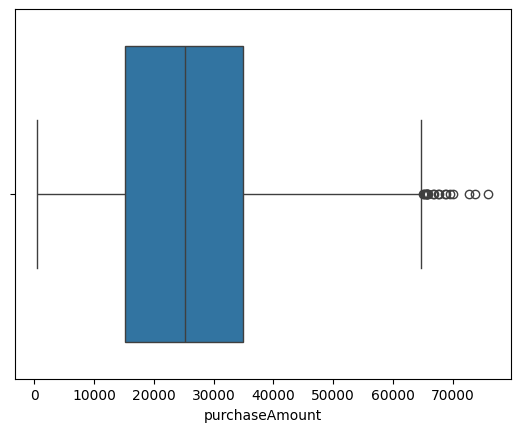

In [373]:
sns.boxplot(x='purchaseAmount', data=df_graph)
plt.show()

## Data distribution

In [376]:
df_graph

,productType,purchaseCurrency,merchantCountryCode,deviceChannel,browserLanguage,purchaseInstalData,browserScreenHeight,browserScreenWidth,browserUserAgent,transStatus,...,challengeWindowSize,purchaseAmount,fraud_label,addrMatch,purchaseAmountBin,purchaseMonth,purchaseTimeBin,purchaseDateBin,billLocation,dateDiffBin
0,ONLINE_PURCHASE,986,250,2,pt-BR,2,1482,1763,Safari,True,...,5.0,39468,False,True,"(37272.2, 75965.0]",2025-10,"[18, 24)",0,Lim,"[365, 730)"
1,ONLINE_PURCHASE,986,76,2,pt-BR,2,1111,986,Safari,True,...,5.0,29746,False,True,"(29047.0, 37272.2]",2025-10,"[0, 6)",3,MS,"[365, 730)"
2,THREE_DS_AND_ONLINE_PURCHASE,986,840,2,pt-BR,1,1317,1515,Other,True,...,5.0,14928,False,True,"(13165.4, 21401.6]",2025-10,"[6, 12)",0,AK,"[180, 365)"
3,THREE_DS_AND_ONLINE_PURCHASE,986,76,2,pt-BR,2,1182,2076,Safari,True,...,5.0,46934,False,True,"(37272.2, 75965.0]",2025-10,"[6, 12)",1,PE,"[730, 1825)"
4,THREE_DS_AND_ONLINE_PURCHASE,986,76,2,en-US,1,1353,2283,Safari,True,...,5.0,26552,False,True,"(21401.6, 29047.0]",2025-10,"[0, 6)",6,PA,"[730, 1825)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,THREE_DS_AND_ONLINE_PURCHASE,986,76,3,es-ES,1,887,2545,Firefox,True,...,NaN,23397,False,True,"(21401.6, 29047.0]",2025-10,"[18, 24)",4,PB,"[365, 730)"
9996,ONLINE_PURCHASE,986,76,2,pt-BR,2,1220,2472,Chrome,True,...,NaN,17563,False,True,"(13165.4, 21401.6]",2025-10,"[12, 18)",6,AM,"[730, 1825)"
9997,ONLINE_PURCHASE,978,76,2,pt-BR,1,684,1419,Safari,True,...,NaN,47669,False,True,"(37272.2, 75965.0]",2025-10,"[18, 24)",1,PA,"[365, 730)"
9998,ONLINE_PURCHASE,986,76,1,pt-BR,1,1050,1127,Firefox,True,...,NaN,31626,False,True,"(29047.0, 37272.2]",2025-10,"[6, 12)",5,RO,"[730, 1825)"


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 2 dimensions. The detected shape was (7, 2) + inhomogeneous part.

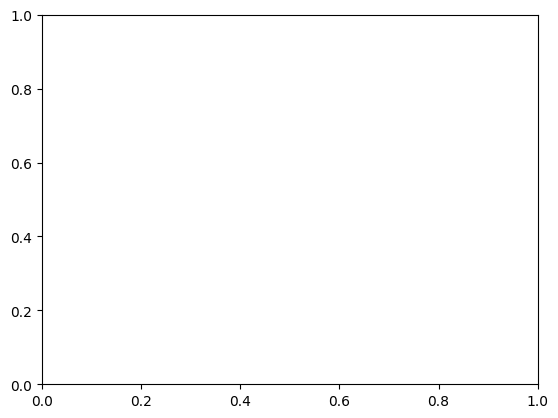

In [379]:
x_amount = df_graph.groupby('purchaseDateBin')
y_amount = df_graph['purchaseAmount'].sum()

plt.plot(x_amount, y_amount)

plt.show()

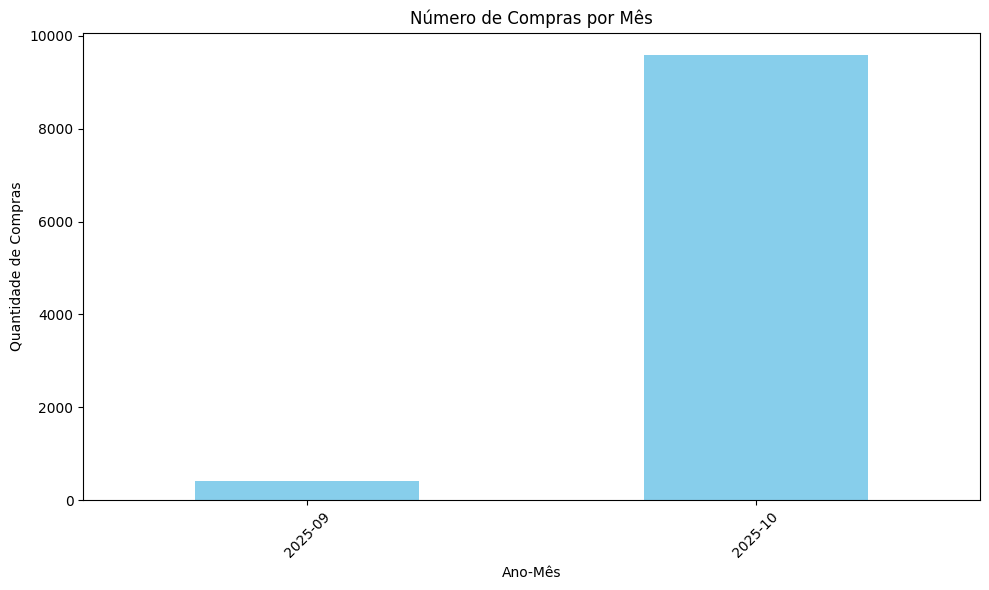

In [305]:
purchase_per_month = df_graph.groupby('purchaseMonth').size()

purchase_per_month.index = purchase_per_month.index.astype(str)

plt.figure(figsize=(10, 6))
purchase_per_month.plot(kind='bar', color='skyblue')

plt.title('Número de Compras por Mês')
plt.xlabel('Ano-Mês')
plt.ylabel('Quantidade de Compras')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


## Interactions

In [380]:
df_graph

,productType,purchaseCurrency,merchantCountryCode,deviceChannel,browserLanguage,purchaseInstalData,browserScreenHeight,browserScreenWidth,browserUserAgent,transStatus,...,challengeWindowSize,purchaseAmount,fraud_label,addrMatch,purchaseAmountBin,purchaseMonth,purchaseTimeBin,purchaseDateBin,billLocation,dateDiffBin
0,ONLINE_PURCHASE,986,250,2,pt-BR,2,1482,1763,Safari,True,...,5.0,39468,False,True,"(37272.2, 75965.0]",2025-10,"[18, 24)",0,Lim,"[365, 730)"
1,ONLINE_PURCHASE,986,76,2,pt-BR,2,1111,986,Safari,True,...,5.0,29746,False,True,"(29047.0, 37272.2]",2025-10,"[0, 6)",3,MS,"[365, 730)"
2,THREE_DS_AND_ONLINE_PURCHASE,986,840,2,pt-BR,1,1317,1515,Other,True,...,5.0,14928,False,True,"(13165.4, 21401.6]",2025-10,"[6, 12)",0,AK,"[180, 365)"
3,THREE_DS_AND_ONLINE_PURCHASE,986,76,2,pt-BR,2,1182,2076,Safari,True,...,5.0,46934,False,True,"(37272.2, 75965.0]",2025-10,"[6, 12)",1,PE,"[730, 1825)"
4,THREE_DS_AND_ONLINE_PURCHASE,986,76,2,en-US,1,1353,2283,Safari,True,...,5.0,26552,False,True,"(21401.6, 29047.0]",2025-10,"[0, 6)",6,PA,"[730, 1825)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,THREE_DS_AND_ONLINE_PURCHASE,986,76,3,es-ES,1,887,2545,Firefox,True,...,NaN,23397,False,True,"(21401.6, 29047.0]",2025-10,"[18, 24)",4,PB,"[365, 730)"
9996,ONLINE_PURCHASE,986,76,2,pt-BR,2,1220,2472,Chrome,True,...,NaN,17563,False,True,"(13165.4, 21401.6]",2025-10,"[12, 18)",6,AM,"[730, 1825)"
9997,ONLINE_PURCHASE,978,76,2,pt-BR,1,684,1419,Safari,True,...,NaN,47669,False,True,"(37272.2, 75965.0]",2025-10,"[18, 24)",1,PA,"[365, 730)"
9998,ONLINE_PURCHASE,986,76,1,pt-BR,1,1050,1127,Firefox,True,...,NaN,31626,False,True,"(29047.0, 37272.2]",2025-10,"[6, 12)",5,RO,"[730, 1825)"


In [381]:
df_graph.dtypes

productType               object
purchaseCurrency           int64
merchantCountryCode        int64
deviceChannel              int64
browserLanguage           object
purchaseInstalData         int64
browserScreenHeight        int64
browserScreenWidth         int64
browserUserAgent          object
transStatus                 bool
eci                        int64
challengeWindowSize      float64
purchaseAmount             int64
fraud_label                 bool
addrMatch                   bool
purchaseAmountBin       category
purchaseMonth          period[M]
purchaseTimeBin         category
purchaseDateBin            int32
billLocation              object
dateDiffBin             category
dtype: object

### productType

In [306]:
amount_per_product_type = df_graph.groupby('productType').agg({
    'purchaseAmount': 'sum',
    'productType': 'count'
}).rename(columns={'productType': 'countProducts',
                   'purchaseAmount': 'totalPurchaseAmount'}).reset_index()

amount_per_product_type

,productType,totalPurchaseAmount,countProducts
0,ONLINE_PURCHASE,178605600,6929
1,THREE_DS,13956993,555
2,THREE_DS_AND_ONLINE_PURCHASE,63986041,2516


### fraud_label

In [307]:
df_graph.groupby('productType')['fraud_label'].value_counts().unstack(fill_value=0)

fraud_label,False,True
productType,,
ONLINE_PURCHASE,6213,716
THREE_DS,492,63
THREE_DS_AND_ONLINE_PURCHASE,2273,243


### browserUserAgent

In [308]:
amount_per_browser = df_graph.groupby('browserUserAgent').agg({
    'purchaseAmount': 'sum',
    'browserUserAgent': 'count'
}).rename(columns={'browserUserAgent': 'countProducts',
                   'purchaseAmount': 'totalPurchaseAmount'}).reset_index().sort_values(by='totalPurchaseAmount', ascending=False)

amount_per_browser

,browserUserAgent,totalPurchaseAmount,countProducts
2,Other,101472718,3937
3,Safari,71653999,2797
0,Chrome,42602308,1646
1,Firefox,40819609,1620


In [309]:
df_graph.groupby('browserUserAgent')['fraud_label'].value_counts().unstack(fill_value=0).sort_values(by=True, ascending=False)

fraud_label,False,True
browserUserAgent,,
Other,3523,414
Safari,2538,259
Firefox,1439,181
Chrome,1478,168


### dateDiffBin

In [310]:
df_graph.groupby('dateDiffBin')['fraud_label'].value_counts().unstack(fill_value=0).sort_values(by=True, ascending=False)

C:\Users\ana.esquinelato\AppData\Local\Temp\ipykernel_20032\2326349832.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_graph.groupby('dateDiffBin')['fraud_label'].value_counts().unstack(fill_value=0).sort_values(by=True, ascending=False)


fraud_label,False,True
dateDiffBin,,
"[730, 1825)",5857,667
"[365, 730)",1974,225
"[180, 365)",1000,114
"[60, 180)",147,16
"[1825, 3650)",0,0


### eci

In [311]:
df_graph.groupby('eci')['fraud_label'].value_counts().unstack(fill_value=0).sort_values(by=True, ascending=False)

fraud_label,False,True
eci,,
7,111,473
0,77,324
5,5937,149
2,2853,76


### addrMatch

In [312]:
df_graph.groupby('addrMatch')['fraud_label'].value_counts().unstack(fill_value=0).sort_values(by=True, ascending=False)

fraud_label,False,True
addrMatch,,
True,8978,1022


### purchaseDateBin

In [313]:
amount_per_date = df_graph.groupby('purchaseDateBin').agg({
    'purchaseAmount': 'sum',
    'purchaseDateBin': 'count'
}).rename(columns={'purchaseDateBin': 'countProducts',
                   'purchaseAmount': 'totalPurchaseAmount'}).reset_index().sort_values(by='totalPurchaseAmount', ascending=False)

amount_per_date

,purchaseDateBin,totalPurchaseAmount,countProducts
1,1,42829376,1693
2,2,41361156,1586
0,0,35470010,1387
5,5,35325322,1397
6,6,34260241,1310
3,3,33740595,1328
4,4,33561934,1299


In [314]:
df_graph.groupby('purchaseDateBin')['fraud_label'].value_counts().unstack(fill_value=0).sort_values(by=True, ascending=False)

fraud_label,False,True
purchaseDateBin,,
1,1509,184
2,1424,162
0,1235,152
6,1174,136
3,1196,132
5,1268,129
4,1172,127


### billLocation

In [315]:
amount_per_location = df_graph.groupby('billLocation').agg({
    'purchaseAmount': 'sum',
    'billLocation': 'count'
}).rename(columns={'billLocation': 'countProducts',
                   'purchaseAmount': 'totalPurchaseAmount'}).reset_index().sort_values(by='totalPurchaseAmount', ascending=False)

amount_per_location

,billLocation,totalPurchaseAmount,countProducts
2,AL,9817691,364
55,MS,9698785,379
73,PA,9132389,351
77,PR,9108194,344
0,AC,8780754,326
...,...,...,...
70,OH,200164,6
105,WI,182978,7
103,VT,182634,8
102,VI,166629,9


### purchaseAmount

In [316]:
amount_per_fraud = df_graph.groupby('fraud_label').agg({
    'purchaseAmount': 'sum',
    'fraud_label': 'count'
}).rename(columns={'fraud_label': 'count',
                   'purchaseAmount': 'totalPurchaseAmount'}).reset_index().sort_values(by='totalPurchaseAmount', ascending=False)

amount_per_fraud

,fraud_label,totalPurchaseAmount,count
0,False,234711888,8978
1,True,21836746,1022


purchaseAmountBin
(499.999, 13165.4]    333
(21401.6, 29047.0]    195
(13165.4, 21401.6]    186
(29047.0, 37272.2]    167
(37272.2, 75965.0]    141
Name: count, dtype: int64

ConversionError: Failed to convert value(s) to axis units: array([Interval(499.999, 13165.4, closed='right'),
       Interval(21401.6, 29047.0, closed='right'),
       Interval(13165.4, 21401.6, closed='right'),
       Interval(29047.0, 37272.2, closed='right'),
       Interval(37272.2, 75965.0, closed='right')], dtype=object)

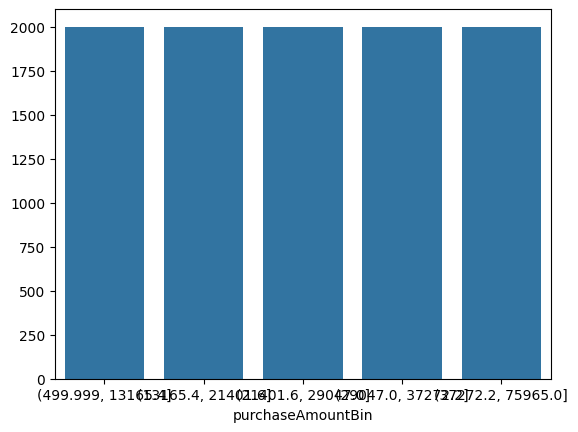

In [338]:
# Config fig
# fig, axes = plt.subplots(3, 2, figsize=(14, 12))
# fig.suptitle('Cluster de Gráficos - Análise Exploratória', fontsize=16)

total_frauds = df_graph[df_graph['fraud_label']]['purchaseAmountBin'].value_counts()

# Distribution by purchase amount bins
# sns.barplot(x=df_graph['purchaseAmountBin'].value_counts().index,
#             y=df_graph['purchaseAmountBin'].value_counts().values, ax=axes[0,0])
# axes[0,0].set_title('Distribuição de Total Compras')
sns.barplot(x=df_graph['purchaseAmountBin'].value_counts().index,
            y=df_graph['purchaseAmountBin'].value_counts().values)
plt.plot(total_frauds.index, total_frauds.values, color='red', marker='o', label='Fraudes por faixa')

plt.legend()
plt.title('Distribuição de Total Compras')
plt.show()

# # Distribution purchase amount by fraud
# sns.barplot(x=df_graph['purchaseAmountBin'].value_counts().index,
#             y=df_graph['purchaseAmountBin'].value_counts().values, ax=axes[0,0])
# axes[0,0].set_title('Distribuição de Total Compras')

# plt.title('Distribuição de Total Compras')
# plt.show()



## Correlação entre as variáveis

In [224]:
df_corr = df_graph.copy()

In [225]:
df_corr.drop(columns=['purchaseAmount'], inplace=True)

In [227]:
df_encoded = pd.get_dummies(df_corr, drop_first=True)

df_encoded

,purchaseCurrency,merchantCountryCode,deviceChannel,purchaseInstalData,browserScreenHeight,browserScreenWidth,transStatus,eci,challengeWindowSize,fraud_label,...,billLocation_WA,billLocation_WI,billLocation_WV,billLocation_WY,billLocation_Wal,billLocation_Ãle,"dateDiffBin_[180, 365)","dateDiffBin_[365, 730)","dateDiffBin_[730, 1825)","dateDiffBin_[1825, 3650)"
0,986,250,2,2,1482,1763,True,5,5.0,False,...,False,False,False,False,False,False,False,True,False,False
1,986,76,2,2,1111,986,True,2,5.0,False,...,False,False,False,False,False,False,False,True,False,False
2,986,840,2,1,1317,1515,True,5,5.0,False,...,False,False,False,False,False,False,True,False,False,False
3,986,76,2,2,1182,2076,True,2,5.0,False,...,False,False,False,False,False,False,False,False,True,False
4,986,76,2,1,1353,2283,True,2,5.0,False,...,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,986,76,3,1,887,2545,True,2,NaN,False,...,False,False,False,False,False,False,False,True,False,False
9996,986,76,2,2,1220,2472,True,2,NaN,False,...,False,False,False,False,False,False,False,False,True,False
9997,978,76,2,1,684,1419,True,2,NaN,False,...,False,False,False,False,False,False,False,True,False,False
9998,986,76,1,1,1050,1127,True,5,NaN,False,...,False,False,False,False,False,False,False,False,True,False


In [228]:
corr_matrix = df_encoded.corr()

TypeError: float() argument must be a string or a real number, not 'Period'